# 05 · Randomized Kaczmarz and CT Image Reconstruction

**Thesis reference:** Chapter 1, Sections 1.5.4–1.5.6 (*Randomized Kaczmarz is Stochastic Gradient Descent for $Ax = b$*, iterated projections, convergence in expectation) and 1.5.10 (*Kaczmarz Method in Tomographic Imaging (CT)*).

The Kaczmarz step projects the current $x$ onto the hyperplane of one equation $a_i^Tx = b_i$:
$$x_{k+1} = x_k + \frac{b_i - a_i^T x_k}{\|a_i\|^2}\, a_i.$$
This is exactly an SGD step on $\frac12(a_i^Tx - b_i)^2$ with step size $1/\|a_i\|^2$.
Strohmer and Vershynin (2009) showed that choosing row $i$ **at random with probability $\|a_i\|^2/\|A\|_F^2$** gives
$$\mathbb{E}\,\|x_k - x^*\|^2 \;\le\; \Big(1 - \frac{\sigma_{\min}^2(A)}{\|A\|_F^2}\Big)^k\, \|x_0 - x^*\|^2.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from pathlib import Path
from skimage.data import shepp_logan_phantom
from skimage.transform import resize, radon, iradon

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Cyclic vs randomized Kaczmarz on a consistent system

We use a random overdetermined system ($500 \times 50$) whose rows have very different lengths.

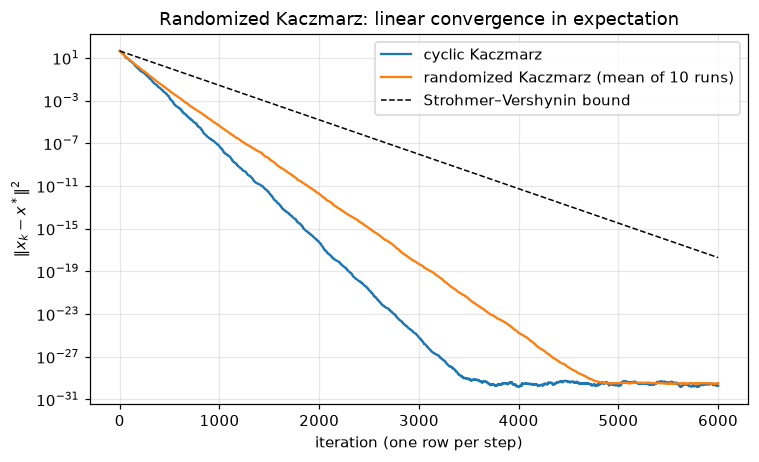

guaranteed contraction per step: 0.99260


In [2]:
rng = np.random.default_rng(0)
m, n = 500, 50
A = rng.standard_normal((m, n)) * rng.uniform(0.1, 3.0, size=(m, 1))
x_star = rng.standard_normal(n)
b = A @ x_star

row_norms2 = np.sum(A**2, axis=1)
probs = row_norms2 / row_norms2.sum()

def kaczmarz(order, iters):
    x = np.zeros(n)
    errs = [np.linalg.norm(x - x_star)**2]
    for k in range(iters):
        i = order(k)
        x += (b[i] - A[i] @ x) / row_norms2[i] * A[i]
        errs.append(np.linalg.norm(x - x_star)**2)
    return np.array(errs)

iters = 6000
cyclic = kaczmarz(lambda k: k % m, iters)
randomized = np.mean([kaczmarz(lambda k, r=np.random.default_rng(s): r.choice(m, p=probs), iters)
                      for s in range(10)], axis=0)

sigma_min = np.linalg.svd(A, compute_uv=False)[-1]
rate = 1 - sigma_min**2 / row_norms2.sum()
bound = rate ** np.arange(iters + 1) * cyclic[0]

plt.figure(figsize=(7, 4.3))
plt.semilogy(cyclic, label="cyclic Kaczmarz")
plt.semilogy(randomized, label="randomized Kaczmarz (mean of 10 runs)")
plt.semilogy(bound, "k--", lw=1, label="Strohmer–Vershynin bound")
plt.xlabel("iteration (one row per step)")
plt.ylabel(r"$\|x_k - x^*\|^2$")
plt.title("Randomized Kaczmarz: linear convergence in expectation")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "05_kaczmarz_convergence.png", bbox_inches="tight")
plt.show()
print(f"guaranteed contraction per step: {rate:.5f}")

On this random system both orders converge, and the cyclic order is even a bit faster. The bound is pessimistic, but it holds **for every ordering of the rows**.
The cyclic method has no such guarantee. If consecutive rows are nearly parallel, each projection makes almost no progress.
The 2D example below has 180 lines through $x^*$ at angles $0^\circ, 1^\circ, 2^\circ, \dots$, taken in that order:

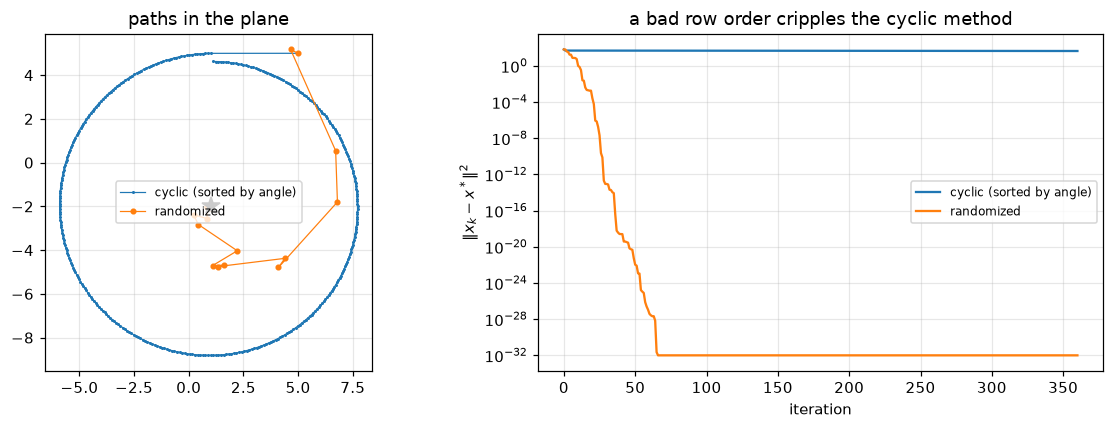

after 360 steps: cyclic error 4.39e+01, randomized error 0.00e+00


In [3]:
angles_2d = np.deg2rad(np.arange(180))
A2 = np.c_[np.cos(angles_2d), np.sin(angles_2d)]
x2_star = np.array([1.0, -2.0])
b2 = A2 @ x2_star

def kaczmarz_2d(order, iters):
    x = np.array([5.0, 5.0])
    path, errs = [x.copy()], [np.sum((x - x2_star)**2)]
    for k in range(iters):
        i = order(k)
        x = x + (b2[i] - A2[i] @ x) * A2[i]          # rows have unit length
        path.append(x.copy()); errs.append(np.sum((x - x2_star)**2))
    return np.array(path), np.array(errs)

r2d = np.random.default_rng(0)
cyc_path, cyc_err = kaczmarz_2d(lambda k: k % 180, 360)
rnd_path, rnd_err = kaczmarz_2d(lambda k: r2d.integers(180), 360)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cyc_path[:, 0], cyc_path[:, 1], ".-", ms=2, lw=0.8, label="cyclic (sorted by angle)")
axes[0].plot(rnd_path[:40, 0], rnd_path[:40, 1], "o-", ms=3, lw=0.8, label="randomized")
axes[0].plot(*x2_star, "k*", ms=12)
axes[0].set_aspect("equal"); axes[0].legend(fontsize=8); axes[0].set_title("paths in the plane")
axes[1].semilogy(cyc_err, label="cyclic (sorted by angle)")
axes[1].semilogy(rnd_err + 1e-32, label="randomized")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel(r"$\|x_k - x^*\|^2$")
axes[1].legend(fontsize=8); axes[1].set_title("a bad row order cripples the cyclic method")
plt.tight_layout()
plt.show()
print(f"after 360 steps: cyclic error {cyc_err[-1]:.2e}, randomized error {rnd_err[-1]:.2e}")

## 2. CT reconstruction (Algebraic Reconstruction Technique)

In computed tomography, X-rays pass through the body at many angles. Each detector reading is a **line integral**: the sum of the unknown pixel densities along one ray.
Stacking all rays gives a large sparse linear system $Ax = b$, where $x$ is the image and $b$ is the measured **sinogram**.
Kaczmarz's method applied to this system is the classic ART algorithm used in early CT scanners.

We build a simple parallel-beam projector: every pixel contributes to the detector bin its centre projects onto.

In [4]:
N = 64
phantom = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)

def projection_matrix(N, angles):
    c = np.arange(N) - (N - 1) / 2
    X, Y = np.meshgrid(c, -c)               # image row 0 is the top
    n_det = int(np.ceil(N * np.sqrt(2))) + 2
    rows, cols = [], []
    pix = np.arange(N * N)
    for a, theta in enumerate(angles):
        t = X.ravel() * np.cos(theta) + Y.ravel() * np.sin(theta)
        bins = np.floor(t + n_det / 2).astype(int)
        rows.append(a * n_det + bins)
        cols.append(pix)
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    A = sp.csr_matrix((np.ones_like(rows, float), (rows, cols)), shape=(len(angles) * n_det, N * N))
    keep = np.diff(A.indptr) > 0             # drop rays that miss the image
    return A[keep], n_det, keep

angles = np.linspace(0, np.pi, 45, endpoint=False)
A_ct, n_det, keep = projection_matrix(N, angles)
x_true = phantom.ravel()
b_clean = A_ct @ x_true
b_noisy = b_clean + 0.01 * np.abs(b_clean).max() * np.random.default_rng(1).standard_normal(b_clean.shape)
print(f"system size: {A_ct.shape[0]} rays x {A_ct.shape[1]} pixels, {A_ct.nnz} nonzeros "
      f"({100 * A_ct.nnz / np.prod(A_ct.shape):.2f}% dense)")

system size: 3656 rays x 4096 pixels, 184320 nonzeros (1.23% dense)


In [5]:
def art(A, b, sweeps, seed=0, nonneg=True, snapshot_at=()):
    """Randomized Kaczmarz on a sparse CSR matrix; optional projection onto x >= 0 after each sweep."""
    rng = np.random.default_rng(seed)
    indptr, indices, data = A.indptr, A.indices, A.data
    norms2 = np.asarray(A.multiply(A).sum(axis=1)).ravel()
    p = norms2 / norms2.sum()
    m = A.shape[0]
    x = np.zeros(A.shape[1])
    errors, snaps = [], {}
    for s in range(1, sweeps + 1):
        for i in rng.choice(m, size=m, p=p):
            lo, hi = indptr[i], indptr[i + 1]
            idx, a = indices[lo:hi], data[lo:hi]
            x[idx] += (b[i] - a @ x[idx]) / norms2[i] * a
        if nonneg:
            np.maximum(x, 0, out=x)
        errors.append(np.linalg.norm(x - x_true) / np.linalg.norm(x_true))
        if s in snapshot_at:
            snaps[s] = x.reshape(N, N).copy()
    return x, np.array(errors), snaps

x_rec, errors, snaps = art(A_ct, b_noisy, sweeps=30, snapshot_at=(1, 5, 30))

# Filtered back-projection (the standard analytic method) on the same 45 angles, for comparison
sino_fbp = radon(phantom, theta=np.degrees(angles), circle=False)
fbp = iradon(sino_fbp, theta=np.degrees(angles), filter_name="ramp", circle=False, output_size=N)
fbp_err = np.linalg.norm(fbp.ravel() - x_true) / np.linalg.norm(x_true)

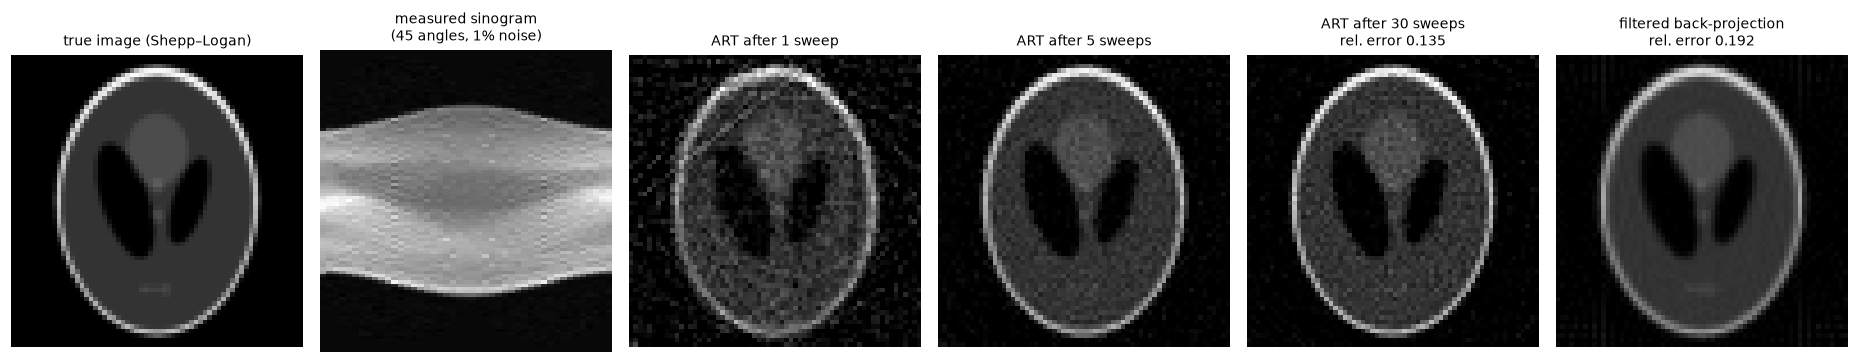

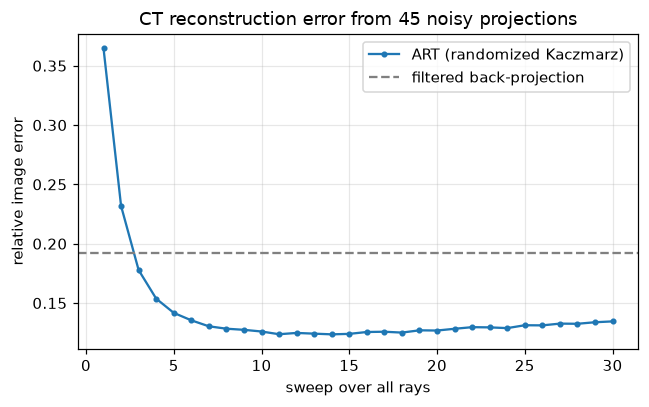

In [6]:
sinogram = np.zeros(len(angles) * n_det)
sinogram[keep] = b_noisy
sinogram = sinogram.reshape(len(angles), n_det).T

fig, axes = plt.subplots(1, 6, figsize=(17, 3.4))
panels = [(phantom, "true image (Shepp–Logan)"), (sinogram, "measured sinogram\n(45 angles, 1% noise)"),
          (snaps[1], "ART after 1 sweep"), (snaps[5], "ART after 5 sweeps"),
          (snaps[30], f"ART after 30 sweeps\nrel. error {errors[-1]:.3f}"),
          (fbp, f"filtered back-projection\nrel. error {fbp_err:.3f}")]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray", aspect="auto" if img is sinogram else "equal",
              vmin=None if img is sinogram else 0, vmax=None if img is sinogram else 1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "05_ct_reconstruction.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 3.8))
plt.plot(np.arange(1, len(errors) + 1), errors, "o-", ms=3, label="ART (randomized Kaczmarz)")
plt.axhline(fbp_err, color="gray", ls="--", label="filtered back-projection")
plt.xlabel("sweep over all rays")
plt.ylabel("relative image error")
plt.title("CT reconstruction error from 45 noisy projections")
plt.legend()
plt.tight_layout()
plt.show()

**Caveat.** The ART data are generated with the same simple projector used for reconstruction, which is an idealized "inverse crime" setting. FBP uses scikit-image's own projector, so the two error numbers illustrate the methods and are not a benchmark.

### Takeaways
* Kaczmarz needs one row of $A$ per step, so it scales to huge sparse systems like CT that are never stored densely.
* Random row selection weighted by $\|a_i\|^2$ gives a provable linear convergence rate that does not depend on how the rows are ordered, and the method is SGD in disguise.
* Iterative methods also make it easy to add prior knowledge, such as non-negative densities, which helps when there are few or noisy projections.